In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold,cross_validate, GridSearchCV, cross_val_predict)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, RocCurveDisplay)

df = pd.read_csv("classification_escalation.csv")
print(df.shape)
display(df.head())
print(df.info())
print(df.isna().sum())
print(df["escalated"].value_counts(normalize=True).rename("proportion"))

print("--------------------------------------")

print("- This is a classification task because the target is a category(escalated or not). it's not a number ")
print("- The positive class is escalated = 1 because that is the target we want to catch.")

(900, 6)


,complexity_score,team_experience_years,priority,channel,customer_tenure_months,escalated
0,9,7.7,low,web,21.6,0
1,2,6.1,high,web,21.8,0
2,1,2.5,medium,phone,28.8,0
3,7,5.3,low,email,52.5,0
4,4,7.1,medium,email,14.7,0


<class 'pandas.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   complexity_score        900 non-null    int64  
 1   team_experience_years   869 non-null    float64
 2   priority                882 non-null    str    
 3   channel                 900 non-null    str    
 4   customer_tenure_months  878 non-null    float64
 5   escalated               900 non-null    int64  
dtypes: float64(2), int64(2), str(2)
memory usage: 42.3 KB
None
complexity_score           0
team_experience_years     31
priority                  18
channel                    0
customer_tenure_months    22
escalated                  0
dtype: int64
escalated
0    0.793333
1    0.206667
Name: proportion, dtype: float64
--------------------------------------
- This is a classification task because the target is a category(escalated or not). it's not a number 
- The positive clas

In [2]:
numeric_cols = ["complexity_score", "team_experience_years", "customer_tenure_months"]
categorical_cols = ["priority", "channel"]

X = df[numeric_cols + categorical_cols]
y = df["escalated"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)
print("train positive rate:", round(y_train.mean(), 3), "| test positive rate:", round(y_test.mean(), 3))

print("--------------------------------------")

print("- Ourr training set is 675 rows while 225 rows are the test sets. stratify=y is used so that a fair share of escalated tickets are split among the training and test set")

(675, 5) (225, 5)
train positive rate: 0.207 | test positive rate: 0.204
--------------------------------------
- Ourr training set is 675 rows while 225 rows are the test sets. stratify=y is used so that a fair share of escalated tickets are split among the training and test set


In [3]:
numeric = Pipeline([
    ("impute", SimpleImputer(strategy="median")),         
    ("scale", StandardScaler()),                          
])
categorical = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),   
    ("onehot", OneHotEncoder(handle_unknown="ignore")),   
])
prep = ColumnTransformer([
    ("num", numeric, numeric_cols),
    ("cat", categorical, categorical_cols),
], sparse_threshold=0)       

def make_model(clf):         
    return Pipeline([("prep", clone(prep)), ("clf", clf)])

In [4]:
print("- Colums that are numeric get median imputation then scaled. columns that are categorical get the most frequent imputation")

- Colums that are numeric get median imputation then scaled. columns that are categorical get the most frequent imputation


In [5]:
models = {
    "Majority baseline": make_model(DummyClassifier(strategy="most_frequent")),
    "Logistic regression": make_model(LogisticRegression(max_iter=1000)),
    "LDA": make_model(LinearDiscriminantAnalysis()),
    "k-NN (k=15)": make_model(KNeighborsClassifier(n_neighbors=15)),
}

rows = []
for name, m in models.items():
    m.fit(X_train, y_train)                      
    pred = m.predict(X_test)                    
    proba = m.predict_proba(X_test)[:, 1]         
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, proba),
    })
comparison = pd.DataFrame(rows)
display(comparison.round(3))

print("------------------------------------------------------------")
print("- Accuracy,precision,recall and f1 are the same because logistic regression and LDA give similar label at 0.5")
print("- ROC-AUC on the other hand when it comes to logistic it is a little higher. K-NN is the weakest")
print("the default  threshold misses most escalation because every model has low recall at 0.5 ")

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Majority baseline,0.796,0.00,0.000,0.000,0.500
1,Logistic regression,0.822,0.75,0.196,0.310,0.811
2,LDA,0.822,0.75,0.196,0.310,0.809
3,k-NN (k=15),0.796,0.50,0.087,0.148,0.705


------------------------------------------------------------
- Accuracy,precision,recall and f1 are the same because logistic regression and LDA give similar label at 0.5
- ROC-AUC on the other hand when it comes to logistic it is a little higher. K-NN is the weakest
the default  threshold misses most escalation because every model has low recall at 0.5 


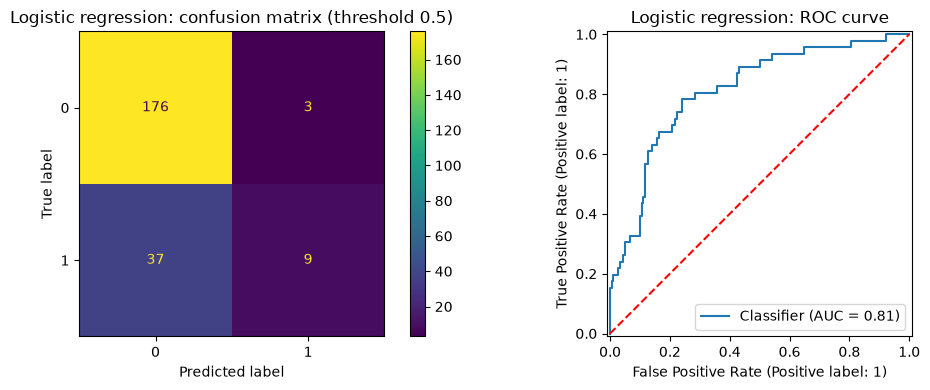

              precision    recall  f1-score   support

           0       0.83      0.98      0.90       179
           1       0.75      0.20      0.31        46

    accuracy                           0.82       225
   macro avg       0.79      0.59      0.60       225
weighted avg       0.81      0.82      0.78       225



In [6]:
logit = models["Logistic regression"]
logit_pred = logit.predict(X_test)
logit_proba = logit.predict_proba(X_test)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, logit_pred, ax=axes[0])
axes[0].set_title("Logistic regression: confusion matrix (threshold 0.5)")
RocCurveDisplay.from_predictions(y_test, logit_proba, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "r--")         
axes[1].set_title("Logistic regression: ROC curve")
plt.tight_layout()
plt.show()
print(classification_report(y_test, logit_pred, zero_division=0))

In [7]:
C_FN, C_FP = 5, 1                                   
thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

def threshold_table(y_true, proba):
    out = []
    for t in thresholds:
        pred = (proba >= t).astype(int)            
        tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
        out.append({
            "Threshold": t,
            "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred, zero_division=0),
            "F1": f1_score(y_true, pred, zero_division=0),
            "FP": fp,
            "FN": fn,
            "Cost (5*FN + FP)": C_FN * fn + C_FP * fp,
        })
    return pd.DataFrame(out)

thr_test = threshold_table(y_test, logit_proba)
display(thr_test.round(3))
best_row = thr_test.loc[thr_test["Cost (5*FN + FP)"].idxmin()]
print("Lowest-cost threshold on the test set:", best_row["Threshold"])

,Threshold,Precision,Recall,F1,FP,FN,Cost (5*FN + FP)
0,0.2,0.429,0.783,0.554,48,10,98
1,0.3,0.549,0.609,0.577,23,18,113
2,0.4,0.571,0.261,0.358,9,34,179
3,0.5,0.750,0.196,0.310,3,37,188
4,0.6,1.000,0.065,0.122,0,43,215
5,0.7,0.000,0.000,0.000,0,46,230


Lowest-cost threshold on the test set: 0.2


In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(
    make_model(KNeighborsClassifier()),
    param_grid={"clf__n_neighbors": [5, 9, 15, 21, 31]},  
    scoring="f1",
    cv=cv,
)
grid.fit(X_train, y_train)

knn_results = pd.DataFrame(grid.cv_results_)[["param_clf__n_neighbors", "mean_test_score", "std_test_score"]]
knn_results.columns = ["k", "mean CV F1", "std"]
display(knn_results.round(3))
print("Best k:", grid.best_params_["clf__n_neighbors"], "| best CV F1:", round(grid.best_score_, 3))

for name in ["Logistic regression", "LDA"]:      
    s = cross_validate(models[name], X_train, y_train, cv=cv, scoring="f1")
    print(name, "CV F1:", round(s["test_score"].mean(), 3))

,k,mean CV F1,std
0,5,0.243,0.095
1,9,0.198,0.065
2,15,0.160,0.065
3,21,0.146,0.056
4,31,0.112,0.040


Best k: 5 | best CV F1: 0.243
Logistic regression CV F1: 0.248
LDA CV F1: 0.266


In [9]:
print("Recommendation")
print("------------------------------------")
print("- Logistic regression with the decision threshold lower than 0.5 is better, used as a decision support for ticket triage rather than an automatic decision maker")
print("- As for model choice K-NN was definitely weaker and LDA and logistic regression performed similar as we said earlier(with ROC-AUC 0.811 vs 0,809) and similar predictions at 0.5 threshold")
print("- In cross-validation LDA's F1 was higher but the gap is still smaller than variation between folds so that still ties.but logistic regression is simple, it's coefficients are easy to explain so that's preferred")
print("- For threshold, at the default(0.5) the model catches only a few escalated tickets(9 of 46) the accuracy is fine. the threshold was compared using cost = 5 x FN + FP. At 0.20 the cost was 98 (FN 10, FP 48), compared with 188 at 0.5, 179 for escalating everything, and 230 for escalating nothing. This is close to the theoretical threshold of 1/6, about 0.167, which comes from the cost ratio. The out-of-fold training predictions also favoured 0.20 on the same grid, so the choice does not rest only on the test set. ")
print("- At the lower threshold the price is a lot of false alarms. at 0.20 the precision is 0.43 which means more than half of the flagged tickets would not have escalated.")
print("- The limitation is that mainly there is a small number of data(only 900 rows) and the test set contains just 46 escalations, so the threshold and cost estimates are noisy and probably a bit optimistic looking at the test table. Some values were missing and imputed.calibration wasn't checked but the formula given assumes calibrated probability and a random split was used and a grouped split could give lower performnce.")
print("- Before deploying since calibration was not used as said in the limitation that should be checked. and also testing on newer tickets, repeating the cross-validation, and comparing errors across priority to look for unfair differences. ")

Recommendation
------------------------------------
- Logistic regression with the decision threshold lower than 0.5 is better, used as a decision support for ticket triage rather than an automatic decision maker
- As for model choice K-NN was definitely weaker and LDA and logistic regression performed similar as we said earlier(with ROC-AUC 0.811 vs 0,809) and similar predictions at 0.5 threshold
- In cross-validation LDA's F1 was higher but the gap is still smaller than variation between folds so that still ties.but logistic regression is simple, it's coefficients are easy to explain so that's preferred
- For threshold, at the default(0.5) the model catches only a few escalated tickets(9 of 46) the accuracy is fine. the threshold was compared using cost = 5 x FN + FP. At 0.20 the cost was 98 (FN 10, FP 48), compared with 188 at 0.5, 179 for escalating everything, and 230 for escalating nothing. This is close to the theoretical threshold of 1/6, about 0.167, which comes from the cost 

In [10]:
print("Questions to answer")
print("----------------------------")
print("1) The tickets that are escalated are about 21%only which means that the model that predicts(not escalated) is much higher with 80% accuracy while no escalation are caught. accuracy does not show the false alarms nor the number of escalations missed.")
print("----------------------------")
print("2) Logistic regression and LDA have the same recall, precision and F1 at threshold 0.5 because their predictions are the same. K-NN is low on all three.")
print("----------------------------")
print("3) As the threshold is lowered more ticket escalation are predicted. recall goes up and false negative goes down but at the same time false positive goes up and precision goes down.")
print("----------------------------")
print("4) the lowest cost is achieved at a threshold of 0.20 on test set. this can be too optimistic because the test set is supposed to be an unseen data and if it is used to pick threshold it might be too good on that one sample, repeated tuning makes it worse so the threshold should be chosen with a cross-validation data and the test set should be used only once at the end.")
print("----------------------------")
print("5) Prior:- how common is the escalation before looking at the ticket(21%)")
print("Likelihood:- how typical the tickets feature is for escalated tickets(high complexity)")
print("Evidence:- how common are those features across all tickets.")
print("Posterior:- the new probability that the ticket is escalated after it's features are visible or seen.")
print("----------------------------")
print("6) Escalating costs 1 × 0.70 = 0.70, because it is only wrong if the ticket would not escalate.")
print("Not escalating costs 5 × 0.30 = 1.50, because it is only wrong if the ticket would escalate. Escalating is cheaper.")
print("Escalate when C_FP(1 − p) < C_FN · p. Rearranging gives p > C_FP / (C_FP + C_FN). With C_FP = 1 and C_FN = 5, the threshold is 1/6 ≈ 0.167. Since 0.30 is above it, escalation is the better action")
print("----------------------------")
print("7) For deployment logistic regression with threshold=0.20 is better because as said earlier it is simpler and also beats K-NN. checks that are required are calibration,repeated cross-validation, error checks across priority and monitoring after deployment.")

Questions to answer
----------------------------
1) The tickets that are escalated are about 21%only which means that the model that predicts(not escalated) is much higher with 80% accuracy while no escalation are caught. accuracy does not show the false alarms nor the number of escalations missed.
----------------------------
2) Logistic regression and LDA have the same recall, precision and F1 at threshold 0.5 because their predictions are the same. K-NN is low on all three.
----------------------------
3) As the threshold is lowered more ticket escalation are predicted. recall goes up and false negative goes down but at the same time false positive goes up and precision goes down.
----------------------------
4) the lowest cost is achieved at a threshold of 0.20 on test set. this can be too optimistic because the test set is supposed to be an unseen data and if it is used to pick threshold it might be too good on that one sample, repeated tuning makes it worse so the threshold shoul